In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import glob
import numpy as np
import re
import unicodedata

folder_path = "Spreadsheets from JCR"
all_dfs = []
for file in os.listdir(folder_path):
    if "LeslieHNicoll" in file and file.endswith(".xlsx"):
        file_path = os.path.join(folder_path, file)
        match = re.search(r"(19|20)\d{2}", file)
        if not match:
            continue        
        year = int(match.group())
        raw = pd.read_excel(file_path, header=None)
        header_row = raw[
            raw.apply(lambda r: r.astype(str)
                      .str.contains("Journal name", na=False)
                      .any(), axis=1)
        ].index
        if len(header_row) == 0:
            continue
        header_row = header_row[0]
        df = pd.read_excel(file_path, header=header_row)
        # remove footer rows
        df = df[~df.iloc[:, 0].astype(str).str.contains("Copyright|Terms of Use", na=False)]
        df.columns = df.columns.str.strip()
        # standardize journal column
        df.rename(columns={"Journal name": "Journal_name"}, inplace=True)
        # add year
        df["Year"] = year
        jif_col = [c for c in df.columns if "JIF" in c and "Quartile" not in c]
        jci_col = [c for c in df.columns if "JCI" in c]
        if len(jif_col) == 1:
            df.rename(columns={jif_col[0]: "JIF"}, inplace=True)
        if len(jci_col) == 1:
            df.rename(columns={jci_col[0]: "JCI"}, inplace=True)
        all_dfs.append(df)
final_df = pd.concat(all_dfs, ignore_index=True, sort=False)
final_df = final_df.dropna(how="all")
final_df = final_df.drop_duplicates(subset=["Journal_name", "Year"])
final_df["JIF"] = pd.to_numeric(final_df.get("JIF"), errors="coerce")
final_df["JCI"] = pd.to_numeric(final_df.get("JCI"), errors="coerce")
final_df["Total Citations"] = pd.to_numeric(final_df.get("Total Citations"), errors="coerce")
final_df = final_df.sort_values(["Journal_name", "Year"]).reset_index(drop=True)
final_df = final_df.dropna(subset=["Journal_name"])
final_df["Journal_name"] = (
    final_df["Journal_name"]
    .astype(str)
    .apply(lambda x: unicodedata.normalize("NFKC", x))
    .str.strip()
    .str.upper())
final_df.head()

C:\Users\mmquazi\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,Journal_name,JCR Abbreviation,Publisher,ISSN,eISSN,Category,Edition,Total Citations,JIF,JIF Quartile,JCI,% of Citable OA,Year
0,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,594.0,NaN,NaN,0.54,0.00%,2020
1,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,747.0,NaN,NaN,0.55,0.00%,2021
2,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,710.0,2.2,NaN,0.77,0.00%,2022
3,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,696.0,2.0,Q2,0.84,1.04%,2023
4,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,730.0,1.5,Q3,0.78,1.08%,2024


In [2]:
# See all columns in the original dataset
print(final_df.columns.tolist())

['Journal_name', 'JCR Abbreviation', 'Publisher', 'ISSN', 'eISSN', 'Category', 'Edition', 'Total Citations', 'JIF', 'JIF Quartile', 'JCI', '% of Citable OA', 'Year']


In [3]:
journal_counts = final_df.groupby('Year')['Journal_name'].nunique().reset_index()
journal_counts.columns = ['Year', 'Unique_Journals']
df_year = final_df.groupby("Year")["Journal_name"].nunique().reset_index()
journal_counts.sort_values('Year').head()

,Year,Unique_Journals
0,1997,41
1,1998,41
2,1999,42
3,2000,43
4,2001,42


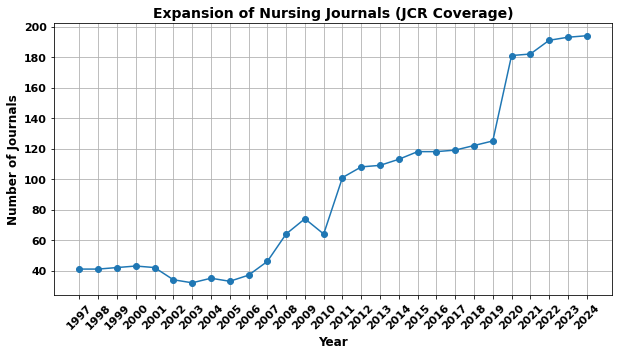

In [4]:
plt.figure(figsize=(10,5))
plt.plot(df_year["Year"], df_year["Journal_name"], marker="o")

plt.title("Expansion of Nursing Journals (JCR Coverage)", fontweight="bold", fontsize=14)
plt.xlabel("Year", fontweight="bold", fontsize=12)
plt.ylabel("Number of Journals", fontweight="bold", fontsize=12)
plt.xticks(df_year["Year"], fontsize=11, fontweight="bold", rotation=45)
plt.yticks(fontsize=11, fontweight="bold")

plt.grid(True)
#plt.savefig("results/figure2.png", dpi=900, bbox_inches="tight")
plt.show()

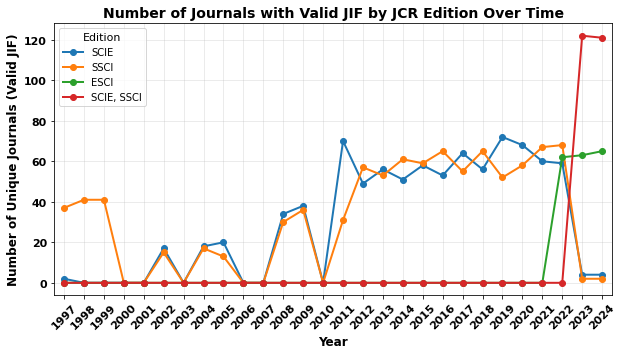

In [5]:
jif_valid = final_df[final_df["JIF"].notna() & (final_df["JIF"] != 0)]

pivot_jif = (
    jif_valid.groupby(["Year", "Edition"])["JCR Abbreviation"]
    .nunique()
    .unstack(fill_value=0)
)

full_years = range(int(final_df["Year"].min()), int(final_df["Year"].max()) + 1)
pivot_jif = pivot_jif.reindex(full_years, fill_value=0)
pivot_jif.index.name = "Year"

order = ["SCIE", "SSCI", "ESCI", "SCIE, SSCI"]
pivot_jif = pivot_jif[[col for col in order if col in pivot_jif.columns]]

plt.figure(figsize=(10,5))
for col in pivot_jif.columns:
    plt.plot(
        pivot_jif.index,
        pivot_jif[col],
        marker="o",
        linewidth=2,
        label=col
    )

plt.title("Number of Journals with Valid JIF by JCR Edition Over Time", fontweight="bold", fontsize=14)
plt.xlabel("Year", fontweight="bold", fontsize=12)
plt.ylabel("Number of Unique Journals (Valid JIF)", fontweight="bold", fontsize=12)
plt.xticks(pivot_jif.index, fontsize=11, fontweight="bold", rotation=45)
plt.yticks(fontsize=11, fontweight="bold")
plt.grid(True, alpha=0.3)

plt.xlim(pivot_jif.index.min() - 0.5, pivot_jif.index.max() + 0.5)

handles, labels = plt.gca().get_legend_handles_labels()
ordered_handles = [handles[labels.index(l)] for l in order if l in labels]
ordered_labels = [l for l in order if l in labels]
plt.legend(ordered_handles, ordered_labels, title="Edition", title_fontsize=11, fontsize=10)

os.makedirs("results", exist_ok=True)
#plt.savefig("results/figure1.png", dpi=900, bbox_inches="tight")
plt.show()